In [ ]:



# 选择一个站点进行分析
station_data = par_data.iloc[:, 1]  

# 傅里叶变换
fft_result = np.fft.fft(station_data)
frequencies = np.fft.fftfreq(len(fft_result))

# 可视化傅里叶变换结果
plt.figure(figsize=(10, 6))
plt.plot(frequencies, np.abs(fft_result))
plt.xlabel('Frequency')
plt.ylabel('Amplitude')
plt.title('Fourier Transform of PAR data')
plt.show()

c:\Users\admin\Desktop\py代码\venv\Lib\site-packages\sklearn\cluster\_kmeans.py:1412: FutureWarning: The default value of `n_init` will change from 10 to 'auto' in 1.4. Set the value of `n_init` explicitly to suppress the warning
  super()._check_params_vs_input(X, default_n_init=10)
c:\Users\admin\Desktop\py代码\venv\Lib\site-packages\sklearn\cluster\_kmeans.py:1412: FutureWarning: The default value of `n_init` will change from 10 to 'auto' in 1.4. Set the value of `n_init` explicitly to suppress the warning
  super()._check_params_vs_input(X, default_n_init=10)
c:\Users\admin\Desktop\py代码\venv\Lib\site-packages\sklearn\cluster\_kmeans.py:1412: FutureWarning: The default value of `n_init` will change from 10 to 'auto' in 1.4. Set the value of `n_init` explicitly to suppress the warning
  super()._check_params_vs_input(X, default_n_init=10)
c:\Users\admin\Desktop\py代码\venv\Lib\site-packages\sklearn\cluster\_kmeans.py:1412: FutureWarning: The default value of `n_init` will change from 10 to

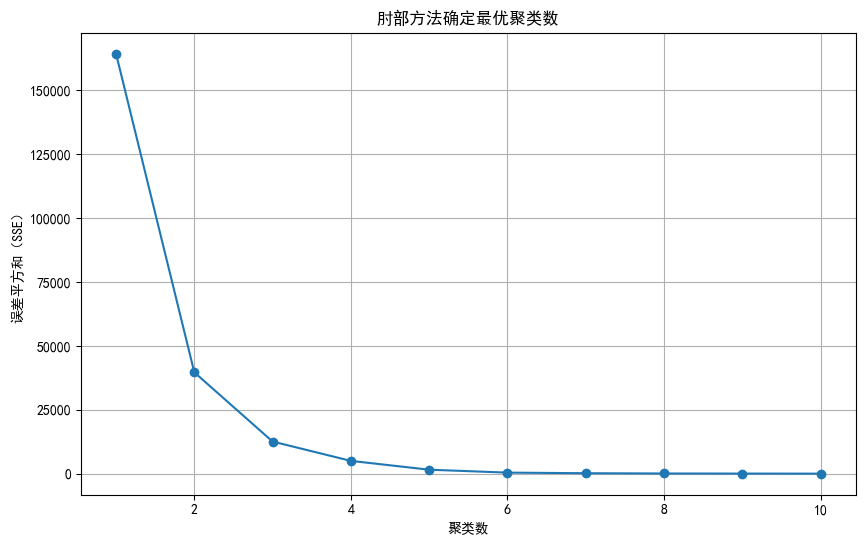

c:\Users\admin\Desktop\py代码\venv\Lib\site-packages\sklearn\cluster\_kmeans.py:1412: FutureWarning: The default value of `n_init` will change from 10 to 'auto' in 1.4. Set the value of `n_init` explicitly to suppress the warning
  super()._check_params_vs_input(X, default_n_init=10)
c:\Users\admin\Desktop\py代码\venv\Lib\site-packages\sklearn\cluster\_kmeans.py:1412: FutureWarning: The default value of `n_init` will change from 10 to 'auto' in 1.4. Set the value of `n_init` explicitly to suppress the warning
  super()._check_params_vs_input(X, default_n_init=10)


         站点      平均PAR值  聚类结果
0     2134m  314.194938     0
14  2218m.1  381.977970     0
12    3481m  272.174885     0
11    3154m  263.609206     0
10    2743m  298.219002     0
9     2453m  309.154666     0
7     1930m  313.147060     0
8     2218m  321.497027     0
5     2246m  265.696474     0
4     2214m  284.408892     0
3     1933m  325.953110     0
2     2160m  327.114804     0
1     2469m  288.198663     0
6     3014m  296.123682     0
16    1735m  292.084147     0
15    2048m  656.978106     1
13    2641m  133.552420     2


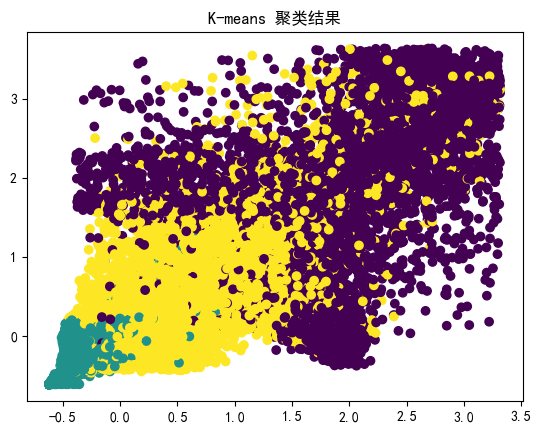

In [20]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

plt.rcParams['font.sans-serif'] = ['SimHei']  #用来正常显示中文标签
plt.rcParams['axes.unicode_minus'] = False  #用来正常显示负号

par_data = pd.read_csv('光合有效辐射.csv')

# 计算每个站点的光合有效辐射（PAR）平均值
mean_par_values = par_data.iloc[:, 1:].mean()

# 将Series转换为DataFrame，便于后续聚类使用
mean_par_values_df = mean_par_values.reset_index()
mean_par_values_df.columns = ['站点', '平均PAR值']

# 使用肘部方法确定最优聚类数
sse = []
for k in range(1, 11):  # 测试从1到10的聚类数
    kmeans = KMeans(n_clusters=k, random_state=42)
    kmeans.fit(mean_par_values_df[['平均PAR值']].values)
    sse.append(kmeans.inertia_)

# 绘制肘部图
plt.figure(figsize=(10, 6))
plt.plot(range(1, 11), sse, marker='o')
plt.title('肘部方法确定最优聚类数')
plt.xlabel('聚类数')
plt.ylabel('误差平方和（SSE）')
plt.grid(True)
plt.show()

# 执行K-means聚类，根据肘部图选择3个聚类
kmeans = KMeans(n_clusters=3, random_state=42)
mean_par_values_df['聚类结果'] = kmeans.fit_predict(mean_par_values_df[['平均PAR值']].values)

# 输出聚类结果
print(mean_par_values_df.sort_values('聚类结果'))

# 提取特征数据
features = par_data.iloc[:, 1:]

# 数据标准化
scaler = StandardScaler()
features_scaled = scaler.fit_transform(features)

# 使用K-means进行聚类
kmeans = KMeans(n_clusters=3, random_state=42)
par_data['Cluster'] = kmeans.fit_predict(features_scaled)

# 可视化聚类结果
plt.scatter(features_scaled[:, 0], features_scaled[:, 1], c=par_data['Cluster'])
plt.title('K-means 聚类结果')
plt.show()



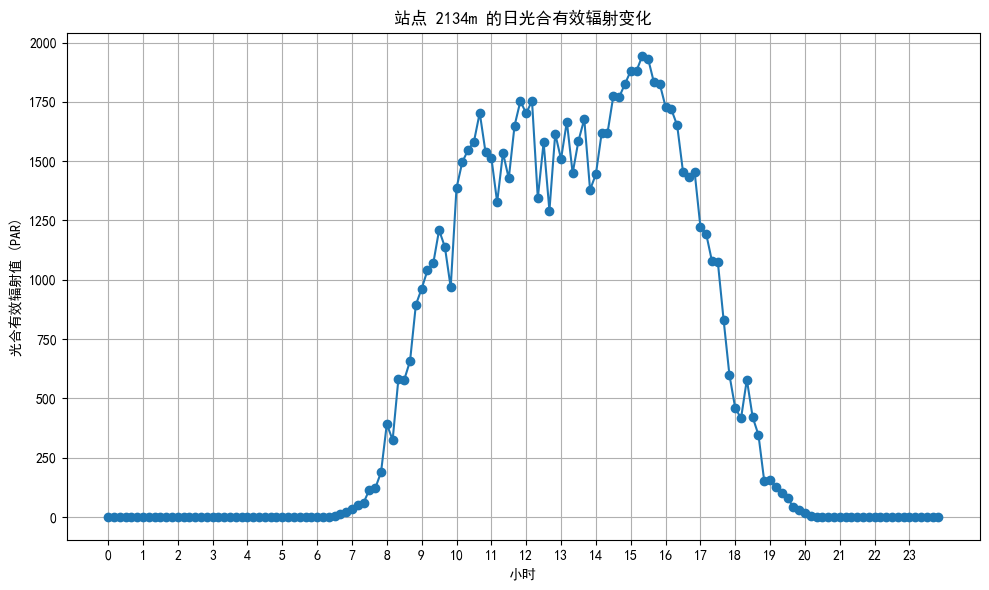

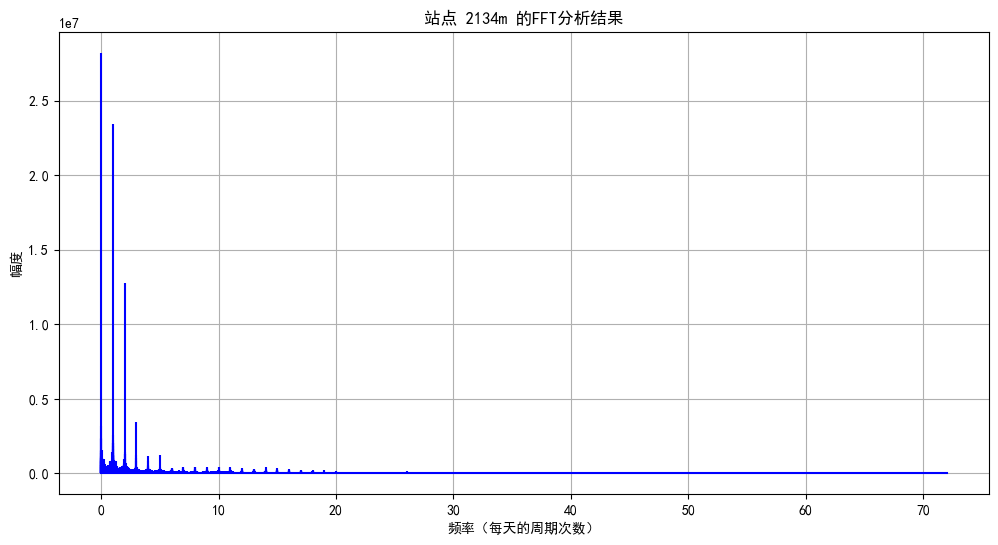

In [9]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# 加载数据并设置时间序列索引
par_data = pd.read_csv('光合有效辐射.csv')
par_data['Unnamed: 0'] = pd.to_datetime(par_data['Unnamed: 0'], format='%Y-%m-%d-%H-%M')
par_data.set_index('Unnamed: 0', inplace=True)

# 日变化分析 - 选择一个具体日期进行分析
date_to_analyze = par_data.index[0].date()
daily_data = par_data[par_data.index.date == date_to_analyze]['2134m']
daily_data_hours = daily_data.index.hour + daily_data.index.minute / 60

# 绘制日变化图
plt.figure(figsize=(10, 6))
plt.plot(daily_data_hours, daily_data.values, marker='o', linestyle='-')
plt.title('站点 2134m 的日光合有效辐射变化')
plt.xlabel('小时')
plt.ylabel('光合有效辐射值 (PAR)')
plt.grid(True)
plt.xticks(range(0, 24))
plt.tight_layout()
plt.show()

# 季节性分析 - 使用FFT分析
fft_values = np.fft.fft(par_data['2134m'].values)
frequencies = np.fft.fftfreq(len(fft_values), d=(1/144))  # 假设每10分钟记录一次，一天144次
positive_frequencies = frequencies[:len(frequencies)//2]
magnitudes = np.abs(fft_values)[:len(frequencies)//2]

# 绘制FFT结果
plt.figure(figsize=(12, 6))
plt.stem(positive_frequencies, magnitudes, 'b', markerfmt=" ", basefmt="-b")
plt.title('站点 2134m 的FFT分析结果')
plt.xlabel('频率（每天的周期次数）')
plt.ylabel('幅度')
plt.grid(True)
plt.show()
